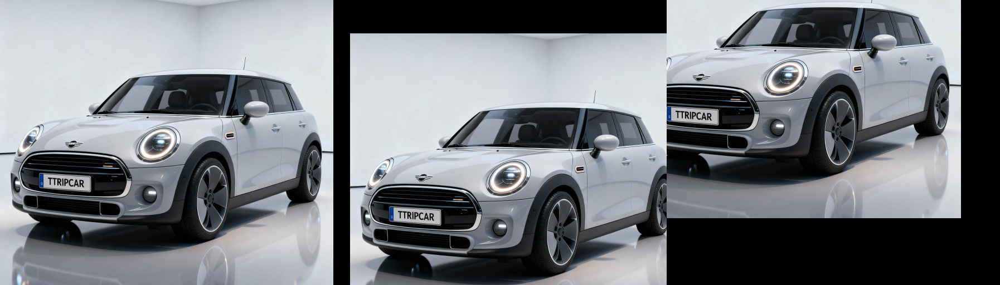

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('미니쿠퍼.jpg')
height, width = image.shape[:2]

M = np.float32([[1, 0, 30], [0, 1, 60]])
M2 = np.float32([[1, 0, -70], [0, 1, -120]])

shiftedImage1 = cv2.warpAffine(image, M, (width, height))
shiftedImage2 = cv2.warpAffine(image, M2, (width, height))

collage_frame = cv2.hconcat([image, shiftedImage1, shiftedImage2])
cv2_imshow(collage_frame)

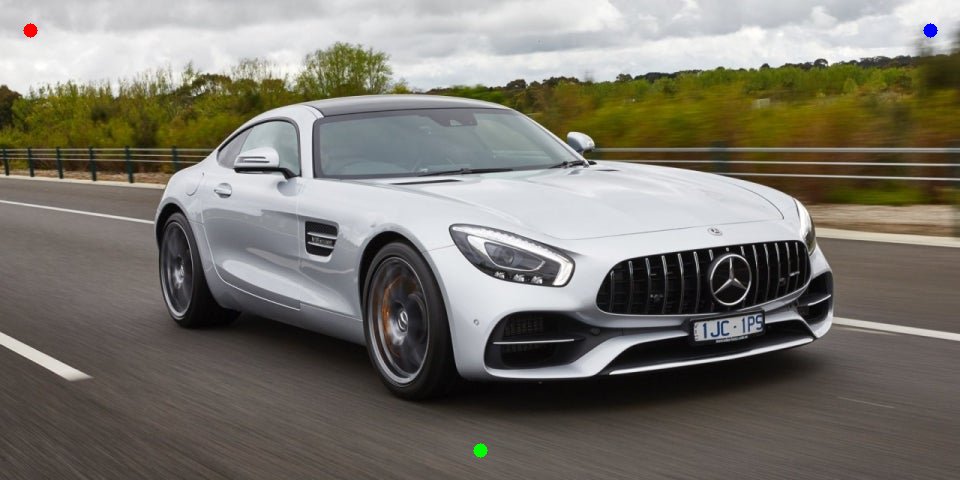

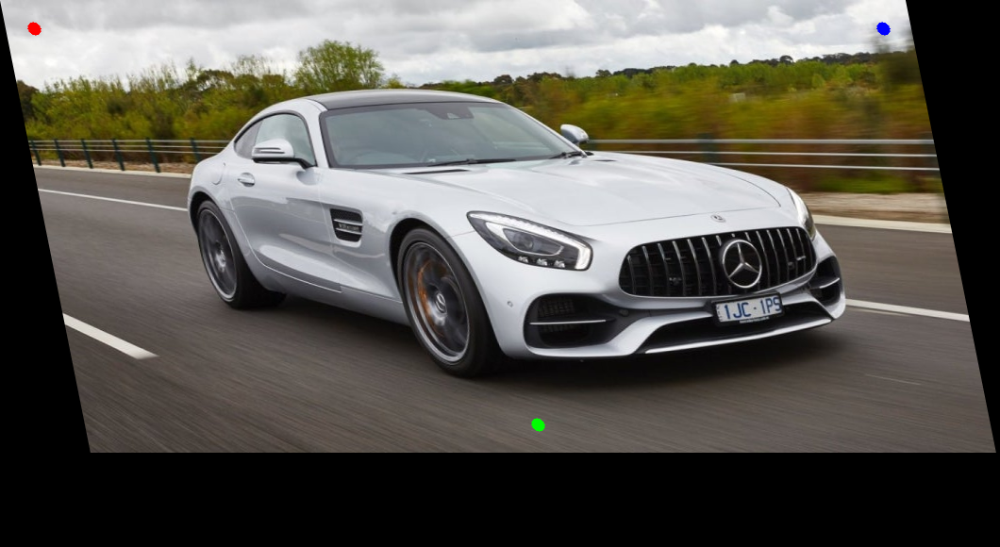

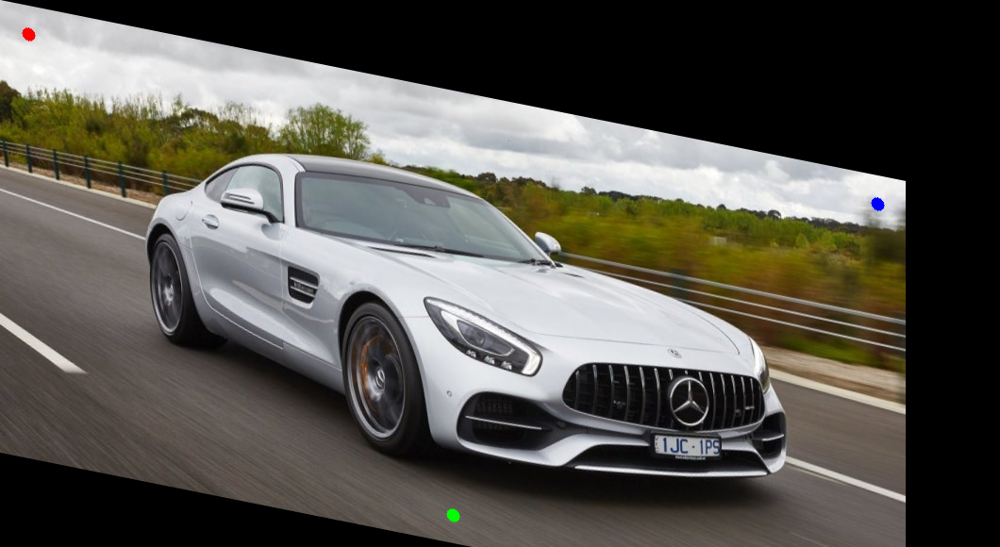

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('벤츠.jpg')
height, width = image.shape[:2]
draw = image.copy()

cv2.circle(draw, (30, 30), 7, (0, 0, 255), -1)
cv2.circle(draw, (width // 2, height - 30), 7, (0, 255, 0), -1)
cv2.circle(draw, (width - 30, 30), 7, (255, 0, 0), -1)
cv2_imshow(draw)

M = np.float32([[1, 0.2, 0],
                [0, 1, 0]])
shearX = cv2.warpAffine(draw, M, (width + 100, height + 100))
cv2_imshow(shearX)

M = np.float32([[1, 0, 0],
                [0.2, 1, 0]])
shearY = cv2.warpAffine(draw, M, (width + 100, height + 100))
cv2_imshow(shearY)

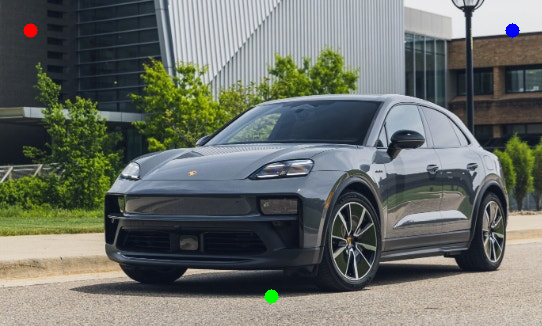

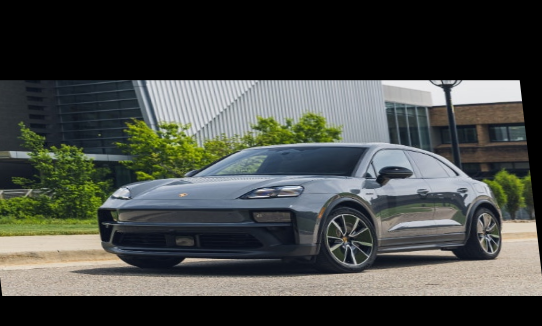

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('포르쉐.jpg')
height, width = image.shape[:2]
draw = image.copy()

cv2.circle(draw, (30, 30), 7, (0, 0, 255), -1)
cv2.circle(draw, (width //2, height - 30), 7, (0, 255, 0), -1)
cv2.circle(draw, (width - 30, 30), 7, (255, 0, 0), -1)

pts1= np.float32([[30, 30], [width // 2, height - 30], [width - 30, 30]])
pts2 = np.float32([[10, 100], [width // 2, height - 50], [width - 50, 100]])

M = cv2.getAffineTransform(pts1, pts2)
dst = cv2.warpAffine(image, M, (width, height))

cv2_imshow(draw)
cv2_imshow(dst)



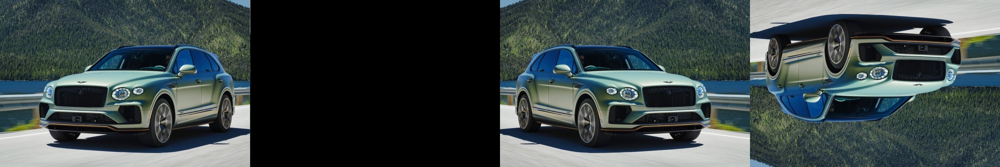

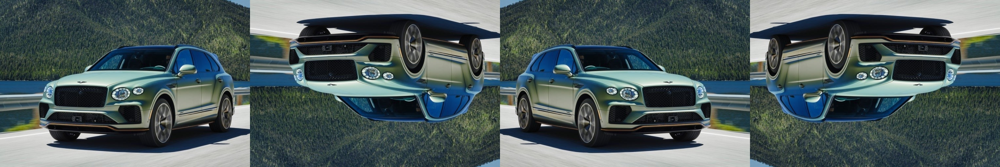

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('벤틀리.jpg')
height, width = image.shape[:2]

M = np.float32([[1, 0, 0], [0, 1, 0]])
notReflected = cv2.warpAffine(image, M, (width, height))

M = np.float32([[-1, 0, 0], [0, -1, height -1]])
xReflected = cv2.warpAffine(image, M, (width, height))

M = np.float32([[-1, 0, width -1], [0, 1, 0]])
yReflected = cv2.warpAffine(image, M, (width, height))

M = np.float32([[-1, 0, width -1], [0, -1, height -1]])
originReflected = cv2.warpAffine(image, M, (width, height))

reflection_frame = cv2.hconcat([notReflected, xReflected, yReflected, originReflected])
cv2_imshow(reflection_frame)

flipvertical = cv2.flip(image, 0)
flipHorizontal = cv2.flip(image, 1)
flipBoth = cv2.flip(image, -1)

flip_frame = cv2.hconcat([image, flipvertical, flipHorizontal, flipBoth])
cv2_imshow(flip_frame)




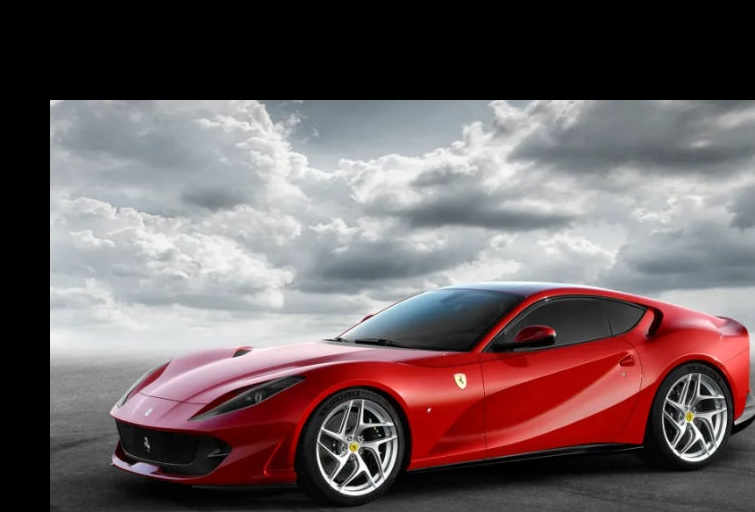

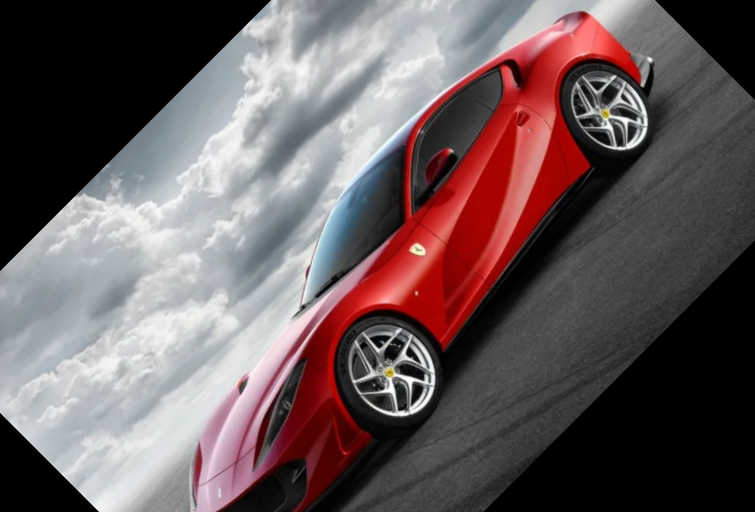

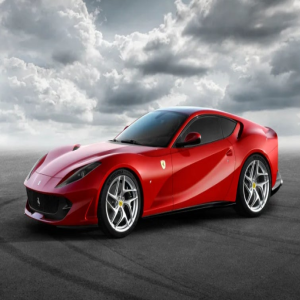

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

def translate(image, x, y):
    M = np.float32([[1, 0, x], [0, 1, y]])
    return cv2.warpAffine(image, M, (image.shape[1], image.shape[0]))

def rotate(image, angle, center=None, scale=1.0):
    h, w = image.shape[:2]
    if center is None:
        center = (w // 2, h //2)
    M = cv2.getRotationMatrix2D(center, angle, scale)
    return cv2.warpAffine(image, M, (w, h))

def resize_keep(image, width=None, height=None, inter=cv2.INTER_AREA):
    h, w = image.shape[:2]
    if width is None and height is None:
        return image
    if width is None:
        r = height / float(h)
        dim = (int(w * r), height)
    elif height is None:
        r = width / float(w)
        dim = (width, int(h * r))
    else:
        dim = (width, height)
    return cv2.resize(image, dim, interpolation=inter)

image = cv2.imread('페라리.jpg')

cv2_imshow(translate(image, 50, 100))
cv2_imshow(rotate(image, 45))
cv2_imshow(resize_keep(image, 300, 300))


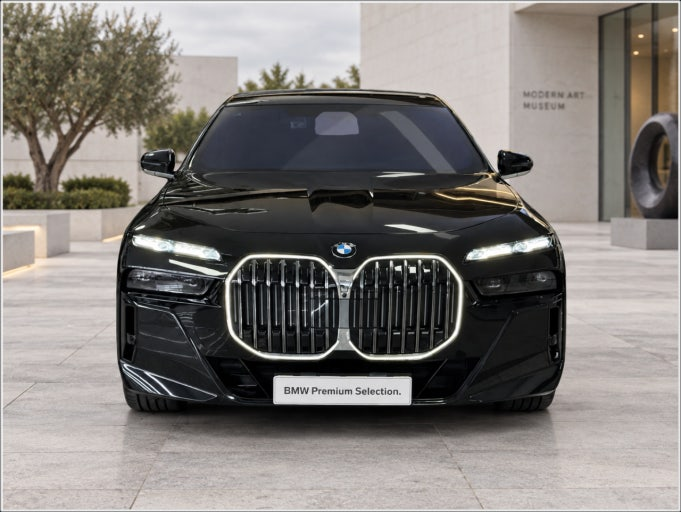

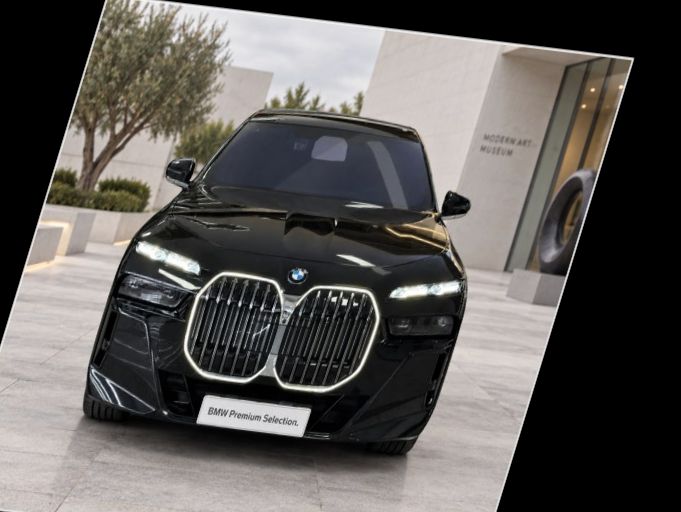

[[ 7.74999937e-01 -3.04017780e-01  1.06771069e+02]
 [ 9.39794319e-02  9.99999939e-01 -6.39999450e+00]]


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('BMW.jpg')
height, width = image.shape[:2]
draw = image.copy()

pointsBefore = np.float32([
    [width * 0.10, height * 0.15],
    [width * 0.50, height * 0.85],
    [width * 0.90, height * 0.15]
])

pointsAfter = np.float32([
    [width * 0.20, height * 0.15],
    [width * 0.35, height * 0.90],
    [width * 0.82, height * 0.25]
])

cv2_imshow(draw)

M = cv2.getAffineTransform(pointsBefore, pointsAfter)
imageResult = cv2.warpAffine(image, M, (width, height))

cv2_imshow(imageResult)
print(M)



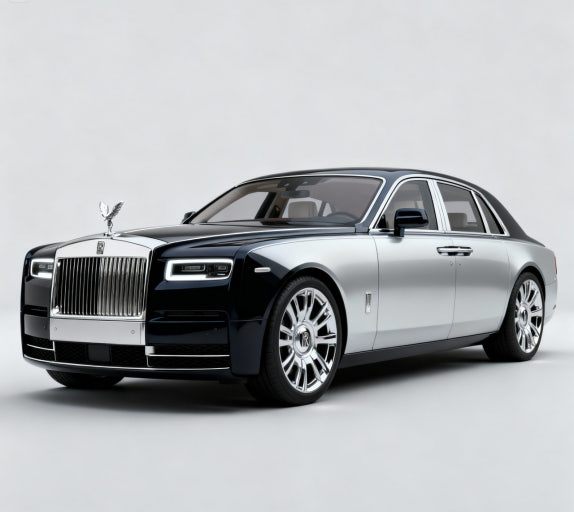

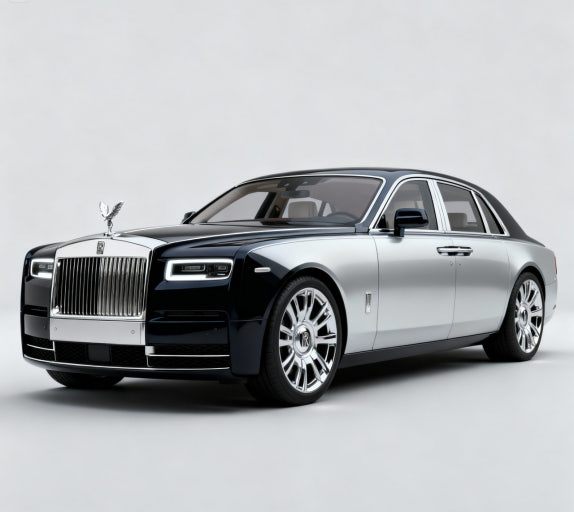

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('롤스로이스.jpeg')
height, width = image.shape[:2]
image2 = image.copy()
draw = image.copy()

pointsBefore = np.float32([
    [width * 0.18, height * 0.30],
    [width * 0.62, height * 0.38],
    [width * 0.36, height * 0.88],
])

pointsAfter = np.float32([
    [width * 0.18, height * 0.30],
    [width * 0.62, height * 0.38],
    [width * 0.36, height * 0.88],
])

M = cv2.getAffineTransform(pointsBefore, pointsAfter)
warped_full = cv2.warpAffine(
    image, M, (width, height), borderMode=cv2.BORDER_REFLECT_101
)

x2, y2, w2, h2 = cv2.boundingRect(pointsAfter.astype(np.int32))
x2, y2 = max(0, x2), max(0, y2)
w2, h2 = min(width - x2, w2), min(height - y2, h2)

roi2 = warped_full[y2 : y2 + h2, x2 : x2 + w2]
pointsAfter_roi = pointsAfter - [x2, y2]

mask = np.zeros((h2, w2), dtype=np.uint8)
cv2.fillConvexPoly(mask, np.int32(pointsAfter_roi), 255)
inverse_mask = cv2.bitwise_not(mask)

roi2_masked = cv2.bitwise_and(roi2, roi2, mask=mask)
image2_bg = cv2.bitwise_and(
     image2[y2 : y2 + h2, x2 : x2 + w2],
     image2[y2 : y2 + h2, x2 : x2 + w2],
     mask=inverse_mask,
)
image2[y2 : y2 + h2, x2 : x2 + w2] = cv2.add(image2_bg, roi2_masked)

cv2_imshow(draw)
cv2_imshow(image2)


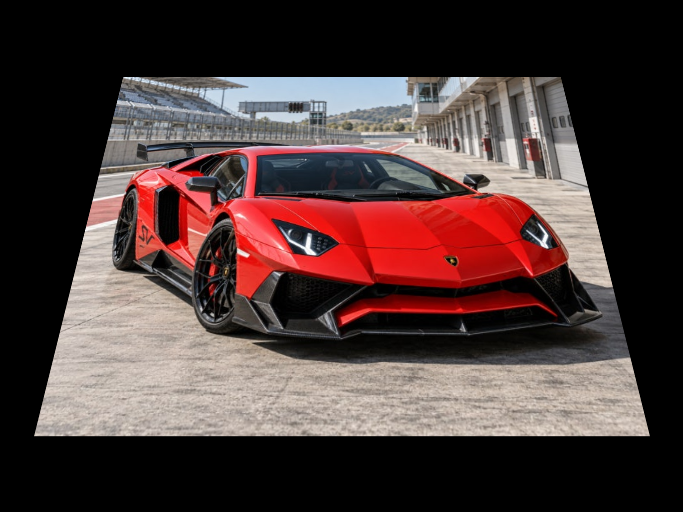

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('람보르기니.jpeg')
h, w = image.shape[:2]

p1 = np.float32([[0,0], [0,h-1], [w-1,0], [w-1,h-1]])
p2 = np.float32([[w*0.18, h*0.15], [w*0.05, h*0.85], [w*0.82, h*0.15], [w*0.95, h*0.85]])

M = cv2.getPerspectiveTransform(p1, p2)
result = cv2.warpPerspective(image, M, (w, h))

cv2_imshow(result)

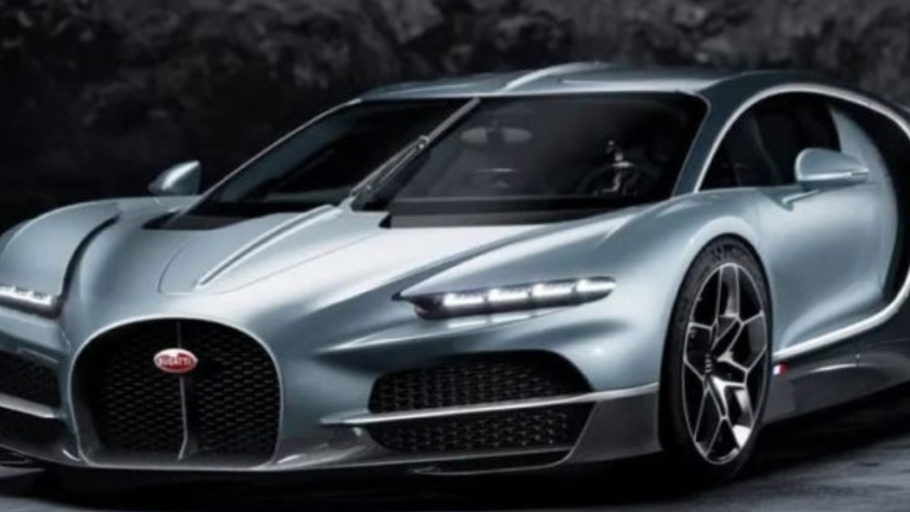

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('부가티.jpeg')
h, w = image.shape[:2]

p8 = np.float32([[w*0.20, h*0.16], [w*0.16, h*0.82], [w*0.84, h*0.82], [w*0.80, h*0.16]])
pA = np.float32([[0, 0], [0, h], [w, h], [w, 0]])

M = cv2.getPerspectiveTransform(p8, pA)
result = cv2.warpPerspective(image, M, (w, h))

cv2_imshow(result)

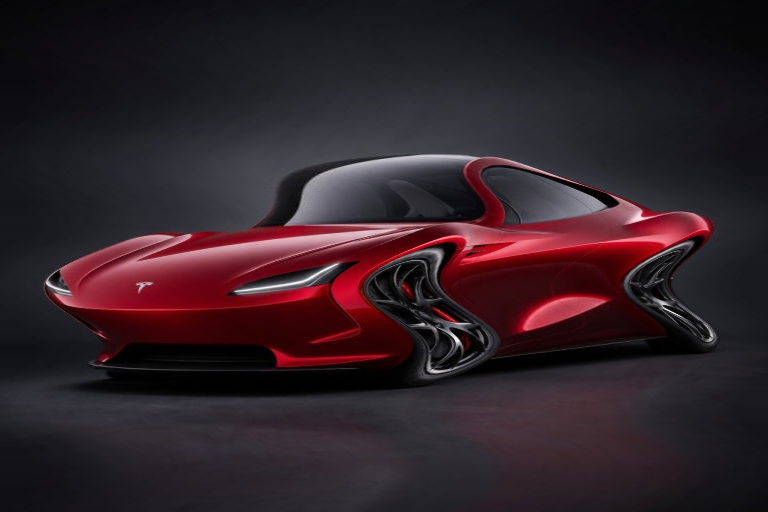

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('테슬라.jpeg')
h, w = image.shape[:2]

mapy, mapx = np.indices((h, w), dtype=np.float32)
sinx = mapx + 30 * np.sin(mapy / 20)

result = cv2.remap(image, sinx, mapy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
cv2_imshow(result)

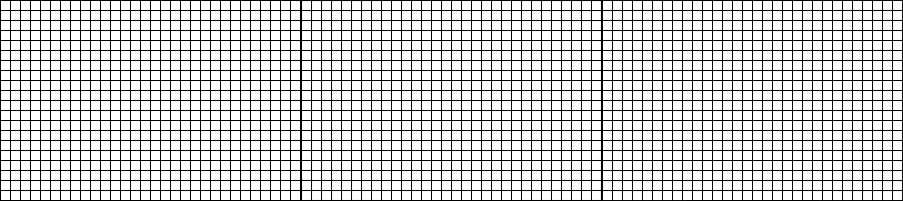

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = np.full((201, 301, 3), 255, np.uint8)
img[::10, :, :] = img[:, ::10, :] = 0

h, w = img.shape[:2]
camM = np.array([[w, 0, w/2], [0, w, h/2], [0, 0, 1]], dtype=np.float32)

barrel = cv2.undistort(img, camM, np.float64([0.001, 0, 0, 0]))
pincushion = cv2.undistort(img, camM, np.float64([-0.001, 0, 0, 0]))
cv2_imshow(cv2.hconcat([img, barrel, pincushion]))

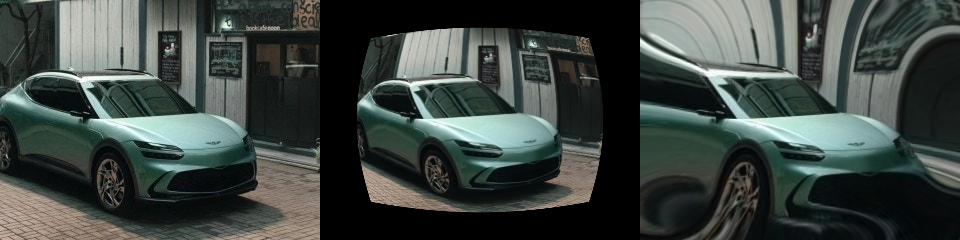

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('제네시스.jpeg')
h, w = img.shape[:2]

y, x = np.indices((h, w), dtype=np.float32)
r, theta = cv2.cartToPolar(2 * x / (w -1) -1, 2 * y / (h-1) -1)

def get_map(k):
    ru = r * (1 + k * (r**2))
    mx, my = cv2.polarToCart(ru, theta)
    return (mx + 1) * (w -1) / 2, (my +1) * (h - 1) / 2

dist_b = cv2.remap(img, *get_map(0.5), cv2.INTER_LINEAR)
dist_p = cv2.remap(img, *get_map(-0.3), cv2.INTER_LINEAR)

cv2_imshow(cv2.hconcat([img, dist_b, dist_p]))

코너 검출 성공


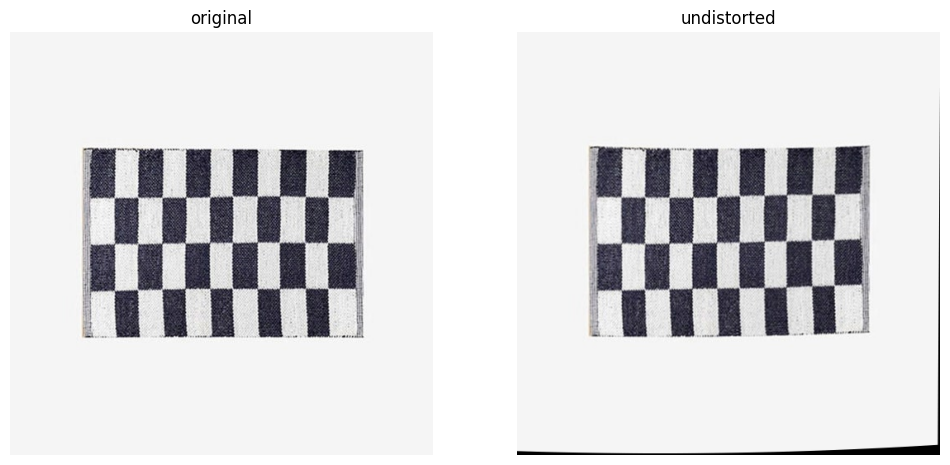

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt

CHECKER_IMAGES = ['체커보드.jpeg']

pattern_size = (9, 3)
objp = np.zeros((np.prod(pattern_size), 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2)
objpoints, imgpoints = [], []

for fname in CHECKER_IMAGES:
    img = cv2.imread(fname)
    if img is None:
        print(f"{fname} 파일을 읽지 못했습니다.")
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ret, corners = cv2.findChessboardCornersSB(gray, pattern_size, None)

    if ret:
        objpoints.append(objp)
        imgpoints.append(corners)
        print("코너 검출 성공")
    else:
        print("코너 검출 실패: pattern_size나 이미지를 확인하세요.")

if len(objpoints) > 0:
    test_img = cv2.imread(CHECKER_IMAGES[0])
    _, mtx, dist, _, _ = cv2.calibrateCamera(objpoints, imgpoints, test_img.shape[:2][::-1], None, None)
    dst_img = cv2.undistort(test_img, mtx, dist, None, mtx)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    ax1.imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)); ax1.set_title('original'); ax1.axis('off')
    ax2.imshow(cv2.cvtColor(dst_img, cv2.COLOR_BGR2RGB)); ax2.set_title('undistorted'); ax2.axis('off')
    plt.show()